# code_026 · Assumptions as testable commitments

**Book:** section 5.5. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_05_GUIDE.md), [execution evidence](../CHAPTER_05_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_026). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=526;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 526


<a id="ledger"></a>
## Turn claims into possible failures

The ledger connects each assumption to a specified test and a response if it fails. Tests can falsify a commitment within their scope; passing a finite suite cannot establish universal validity. Stress observations below come from separate declared mechanisms rather than adaptive reuse of a final field sample. Their exact references are known only because we wrote the toy generators.


In [2]:
ledger=pd.DataFrame([
 ['Linearity','predict a high-load nonlinear response','restrict range or change representation'],
 ['Locality','query a gap far from observed combinations','flag support and collect nearby cases'],
 ['Stationarity','shift a later-window measurement offset','audit sensor state and reevaluate'],
 ['Exchangeability','compare histories with shared building offsets','split and summarize by building'],
 ['Rotation invariance','rotate load with anisotropic stiffness fixed','retain direction or transform target correctly'],
 ['Physical model','check equilibrium, units and held-out observations','investigate boundary/model mismatch']
],columns=['commitment','stress test','possible response']);display(ledger)
assert len(ledger)==6 and not ledger.isna().any().any()


,commitment,stress test,possible response
0,Linearity,predict a high-load nonlinear response,restrict range or change representation
1,Locality,query a gap far from observed combinations,flag support and collect nearby cases
2,Stationarity,shift a later-window measurement offset,audit sensor state and reevaluate
3,Exchangeability,compare histories with shared building offsets,split and summarize by building
4,Rotation invariance,rotate load with anisotropic stiffness fixed,retain direction or transform target correctly
5,Physical model,"check equilibrium, units and held-out observat...",investigate boundary/model mismatch


<a id="response"></a>
## A linear fit can fail beyond the observed regime

Fit an affine observation rule on 80 independent training loads x in [0,.6], where x=P/(1000 N), response y=.2+1.2*x+.8*x³+noise sd .02 mm. Compare fixed in-range and high-load grids against the noiseless generator, not against a repeatedly consulted final set. The observed intercept is a measurement offset. A high-load failure may be an extrapolation problem, an incorrect family or both.


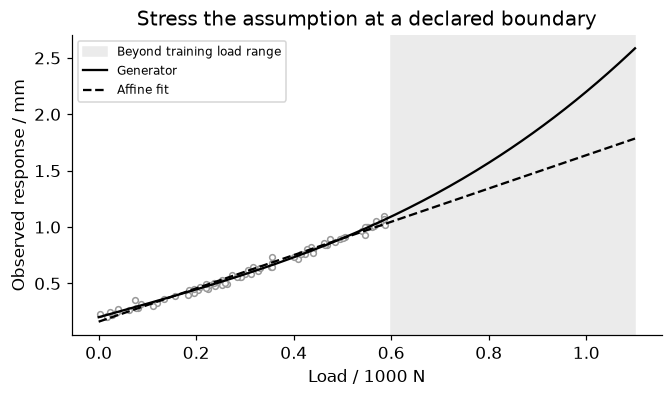

In [3]:
response=lambda x:.2+1.2*x+.8*x**3
x=rng.uniform(0,.6,80);y=response(x)+rng.normal(0,.02,80);A=np.column_stack([np.ones(80),x]);w=np.linalg.lstsq(A,y,rcond=None)[0]
inside=np.linspace(.05,.55,80);outside=np.linspace(.8,1.1,80)
predict=lambda z:np.column_stack([np.ones(len(z)),z])@w
errors=[float(np.sqrt(np.mean((predict(z)-response(z))**2))) for z in [inside,outside]]
assert errors[1]>errors[0] and np.linalg.norm(A.T@(A@w-y))<1e-12
fig,ax=plt.subplots(figsize=(6,3.5));line=np.linspace(0,1.1,200);ax.axvspan(.6,1.1,color='.92',label='Beyond training load range');ax.scatter(x,y,s=14,facecolors='white',edgecolors='.6');ax.plot(line,response(line),'k-',label='Generator');ax.plot(line,predict(line),'k--',label='Affine fit')
ax.set(xlabel='Load / 1000 N',ylabel='Observed response / mm',title='Stress the assumption at a declared boundary');ax.legend(fontsize=8);plt.show()
RESULTS['in_out_range_generator_RMSE_mm']=errors


<a id="sampling"></a>
## Locality, stationarity and sampling unit

A gap query can be in the bounding box yet remote from the observed cloud. Separately, an unmodeled +.3 mm later-window sensor offset changes the observation process. A third constructed repeated-building sample has shared offsets: row count is not the independent-building count. Permuting a table does not make its generating mechanism exchangeable across deployment time. Conversely, exchangeability does not require independence: a shared latent offset can yield an exchangeable but dependent sequence within one building.

These are mechanism checks, not hypothesis tests with calibrated p-values. Time direction, building IDs and sensor metadata carry evidence that numerical residuals alone cannot identify.


In [4]:
t=np.linspace(0,1,50);cloud=np.column_stack([t,t]);query=np.array([.1,.9]);distance=float(np.linalg.norm(cloud-query,axis=1).min())
assert np.all((query>=cloud.min(0))&(query<=cloud.max(0))) and distance>.5
before=response(inside);later=before+.3
assert np.allclose(later-before,.3) and np.isclose(np.mean((later-before)**2),.09)
shared=rng.normal(0,.4,12);epsilon=rng.normal(0,.03,(12,30));readings=shared[:,None]+epsilon
within=float(np.var(readings-readings.mean(1,keepdims=True)));between=float(np.var(readings.mean(1)))
assert readings.size==360 and len(shared)==12 and within<between
RESULTS['gap_distance']=distance;RESULTS['later_offset_mm']=.3;RESULTS['within_between_variance_mm2']=[within,between]


<a id="symmetry"></a>
## Physical rotation is not just a coordinate change

An ideal linear spring has symmetric positive definite K=diag(1000,4000) N/m, force f N and displacement u=solve(K,f) m. For equal 500 N magnitudes along the two principal directions, displacement magnitudes differ. Rotating the physical force while holding anisotropic K fixed is not a target-preserving augmentation.

For a change of orthonormal coordinates R, transform both K'=R K R.T and f'=R f. Then u'=R u: equivariance. A small equilibrium residual confirms this declared solve. It cannot prove that real stiffness, measured forces or boundary conditions match this toy model.


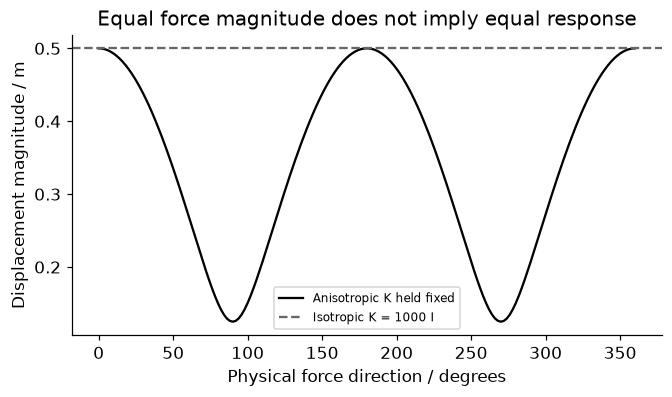

In [5]:
K=np.diag([1000.,4000.]);forces=np.array([[500.,0.],[0.,500.]])
u=np.linalg.solve(K,forces.T).T;norms=np.linalg.norm(u,axis=1)
assert np.all(np.linalg.eigvalsh(K)>0) and np.allclose(norms,[.5,.125])
assert np.isclose(np.linalg.norm(forces[0]),np.linalg.norm(forces[1])) and not np.isclose(*norms)
a=.7;R=np.array([[np.cos(a),-np.sin(a)],[np.sin(a),np.cos(a)]]);f=forces[0];displacement=u[0]
Kprime=R@K@R.T;fprime=R@f;uprime=np.linalg.solve(Kprime,fprime)
assert np.allclose(uprime,R@displacement) and np.linalg.norm(K@displacement-f)<1e-10
angles=np.linspace(0,2*np.pi,181);F=500*np.column_stack([np.cos(angles),np.sin(angles)]);U=np.linalg.solve(K,F.T).T
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot(angles*180/np.pi,np.linalg.norm(U,axis=1),'k-',label='Anisotropic K held fixed');ax.axhline(.5,color='.4',ls='--',label='Isotropic K = 1000 I')
ax.set(xlabel='Physical force direction / degrees',ylabel='Displacement magnitude / m',title='Equal force magnitude does not imply equal response');ax.legend(fontsize=8);plt.show()
RESULTS['equal_force_direction_displacement_m']=norms.tolist();RESULTS['coordinate_equivariance_max_error_m']=float(np.max(abs(uprime-R@displacement)))


<a id="exercises"></a>
## Exercises and hints

1. Give each ledger row a measured signal, acceptance criterion, test population and action owner. Which thresholds require application consequences?
2. Design a later-time holdout that keeps preprocessing and future sensor recalibration unavailable during fitting.
3. Make an independent load–direction grid for a chosen model. Separate interpolation, novel combinations and high-load extrapolation.
4. Add a physically incorrect stiffness that still solves its own equilibrium equation. Explain why a zero residual is insufficient validation.
5. State whether a scalar output is invariant or a vector is equivariant under a coordinate transformation. Transform units and boundaries consistently.

**Hints:** failures can concern the data process, representation, family, algorithm or physical approximation. A support flag is not calibrated uncertainty. A synthetic stress suite reveals consequences of declared assumptions rather than certifying a structure.


In [6]:
summary={'example_id':'code_026','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['assumption ledger with observable stress tests', 'linearity and load extrapolation', 'local support and stationarity failures', 'exchangeability as a sampling commitment', 'anisotropic rotation versus coordinate equivariance', 'physical residual versus empirical validity'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["assumption ledger with observable stress tests", "linearity and load extrapolation", "local support and stationarity failures", "exchangeability as a sampling commitment", "anisotropic rotation versus coordinate equivariance", "physical residual versus empirical validity"], "elapsed_seconds": 0.146, "example_id": "code_026", "hardware": "Darwin arm64 CPU", "results": {"coordinate_equivariance_max_error_m": 5.551115123125783e-17, "equal_force_direction_displacement_m": [0.5, 0.125], "gap_distance": 0.5658694607097398, "in_out_range_generator_RMSE_mm": [0.015918199438280742, 0.5086008290050557], "later_offset_mm": 0.3, "within_between_variance_mm2": [0.0008335641398601035, 0.1809428473127238]}, "seed": 526, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
